Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2541 - loss: 2.0383 - val_accuracy: 0.3375 - val_loss: 1.8530
Epoch 2/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3332 - loss: 1.8502 - val_accuracy: 0.3575 - val_loss: 1.7809
Epoch 3/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3606 - loss: 1.7833 - val_accuracy: 0.3895 - val_loss: 1.7223
Epoch 4/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3732 - loss: 1.7393 - val_accuracy: 0.3964 - val_loss: 1.6874
Epoch 5/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3942 - loss: 1.7012 - val_accuracy: 0.3981 - val_loss: 1.6716
Epoch 6/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4046 - loss: 1.6652 - val_accuracy: 0.4105 - val_loss: 1.6557
Epoch 7/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4125 - loss: 1.6453 - val_accuracy: 0.4141 - val_loss: 1.6526
Epoch 8/11
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4193 - loss: 1.6284 - val_accuracy: 0.

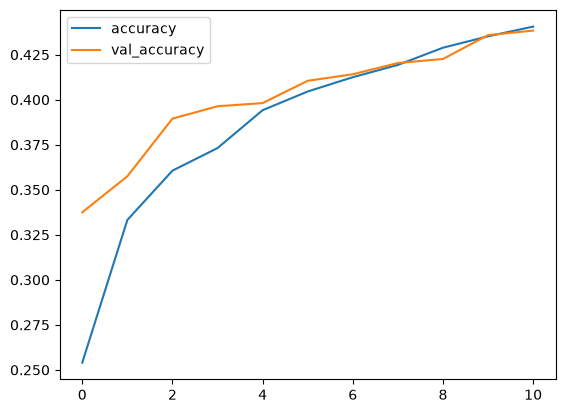

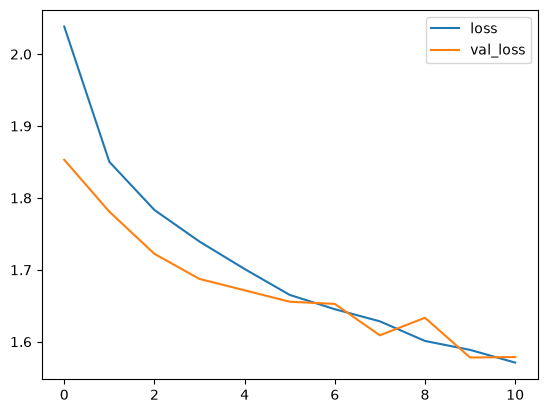

In [4]:
# a. Import necessary packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split

# b. Load dataset

df = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/FNN and CNN/CIFAR10/cifar-10.csv")

# Separate features and labels
X = df.drop(['label'], axis=1).values
y = df['label'].values

# Split training and testing data
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalize data
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# c. Define network architecture using Keras

model = Sequential()
model.add(Dense(128, input_shape=(3072,), activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(10, activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# d. Train the model using SGD with 11 epochs

history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2
)

# e. Evaluate the network

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

# f. Plot training loss and accuracy

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()